In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import Perceptron, LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, PowerTransformer

# estudo árvores
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from src.config import DADOS_LIMPOS
from src.graficos import plot_comparar_metricas_modelos
from src.models import RANDOM_STATE
from src.models import (
    grid_search_cv_classificador,
    treinar_e_validar_modelo_classificacao,
    organiza_resultados,
)

sns.set_theme(palette="bright")

In [3]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [4]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [5]:
le = LabelEncoder()

y = le.fit_transform(y)

y[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [6]:
seletor_mi = SelectKBest(mutual_info_classif, k=15)

X_mi = seletor_mi.fit_transform(X, y)

X_mi.shape

(569, 15)

In [7]:
seletor_mi.get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [8]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [9]:
preprocessamento = Pipeline(
    steps=[
        ("scaler", PowerTransformer()),
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

preprocessamento_arvore = Pipeline(
    steps=[
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

In [10]:
classificadores = {
    "DummyClassifier": {
        "preprocessor": None,
        "classificador": DummyClassifier(strategy="stratified")
    },
    "Perceptron": {
        "preprocessor": preprocessamento,
        "classificador": Perceptron()
    },
    "LogisticRegression": {
        "preprocessor": preprocessamento,
        "classificador": LogisticRegression()
    },
    "SGDClassifier": {
        "preprocessor": preprocessamento,
        "classificador": SGDClassifier()
    },
    
    # adicionar modelos baseados em árvores de decisão

    "DecisionTreeClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": DecisionTreeClassifier()
    },
}

In [11]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_classificacao(X, y, kf, **classificador)
    for nome_modelo, classificador in classificadores.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

,model,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
0,DummyClassifier,0.001355,0.012469,0.517544,0.488863,0.367816,0.363636,0.372093,0.505077,0.379615,0.013824
1,DummyClassifier,0.000928,0.010143,0.473684,0.426138,0.25,0.27027,0.232558,0.528333,0.391598,0.01107
2,DummyClassifier,0.002053,0.007518,0.561404,0.518849,0.375,0.394737,0.357143,0.493056,0.365272,0.009572
3,DummyClassifier,0.000946,0.006418,0.570175,0.530754,0.395062,0.410256,0.380952,0.496032,0.366598,0.007364
4,DummyClassifier,0.001045,0.00444,0.513274,0.466801,0.303797,0.324324,0.285714,0.580483,0.420884,0.005485
5,Perceptron,0.110666,0.012198,0.938596,0.918605,0.911392,1.0,0.837209,0.987881,0.982831,0.122864
6,Perceptron,0.079707,0.00592,0.894737,0.865051,0.842105,0.969697,0.744186,0.985915,0.977328,0.085628
7,Perceptron,0.058629,0.006321,0.921053,0.922619,0.896552,0.866667,0.928571,0.982143,0.978283,0.064951
8,Perceptron,0.060918,0.006736,0.95614,0.960317,0.942529,0.911111,0.97619,0.995701,0.993515,0.067654
9,Perceptron,0.061635,0.005392,0.964602,0.952381,0.95,1.0,0.904762,0.996982,0.995172,0.067027


In [12]:
df_resultados.groupby("model").mean().sort_values("test_recall")

,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
model,,,,,,,,,,
DummyClassifier,0.001265,0.008198,0.527216,0.486281,0.338335,0.352645,0.325692,0.520596,0.384793,0.009463
DecisionTreeClassifier,0.04797,0.006051,0.906893,0.899021,0.872924,0.88373,0.867996,0.899021,0.814852,0.054021
Perceptron,0.074311,0.007313,0.935026,0.923795,0.908516,0.949495,0.878184,0.989724,0.985426,0.081625
SGDClassifier,0.066507,0.007551,0.950815,0.945228,0.933149,0.945823,0.924142,0.989973,0.987059,0.074058
LogisticRegression,0.068839,0.008511,0.952585,0.947818,0.935613,0.944606,0.929125,0.992078,0.989293,0.077349


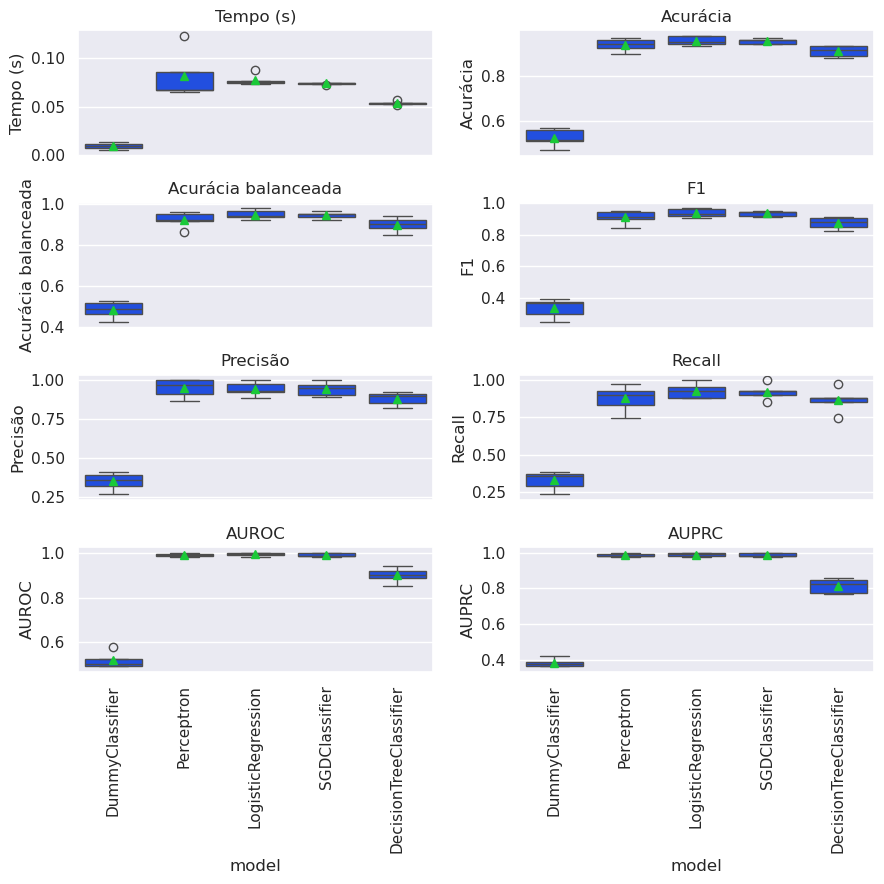

In [13]:
plot_comparar_metricas_modelos(df_resultados)

Hiperparâmetros usualmente utilizados para otimizar DecisionTreeClassifier:

- **`max_depth`**: Limita a profundidade da árvore, prevenindo overfitting.
- **`min_samples_split`**: Número mínimo de amostras para dividir um nó.
- **`min_samples_leaf`**: Mínimo de amostras em um nó folha.
- **`max_features`**: Número de features a serem consideradas na divisão.
- **`criterion`**: Função para medir a qualidade da divisão.
- **`splitter`**: Estratégia de divisão dos nós.
- **`class_weight`**: Ponderação das classes para lidar com desbalanceamento.
- **`ccp_alpha`**: Controla a poda de custo-complexidade. Maior valor resulta em mais poda.


**Pré-poda (pre-pruning)** e **pós-poda (post-pruning)** são técnicas usadas para controlar a complexidade de uma árvore de decisão e evitar o overfitting:

- **Pré-poda**: A árvore para de crescer antes que todas as folhas sejam puras. Limites são impostos durante o crescimento, como definir um `max_depth`, `min_samples_split`, ou `min_samples_leaf`. Evita a criação de nós desnecessários desde o início.

- **Pós-poda**: A árvore é completamente construída e, em seguida, ramos irrelevantes ou muito específicos são removidos. O hiperparâmetro `ccp_alpha` (poda de custo-complexidade) é um exemplo de pós-poda.

O **custo-complexidade** é uma técnica de poda que busca equilibrar a complexidade da árvore de decisão com a qualidade da predição. O objetivo é encontrar um ponto ótimo onde a árvore seja suficientemente complexa para explicar os dados, mas não tão complexa a ponto de overfitting. 

A fórmula de custo-complexidade combina o erro de predição da árvore com um termo de penalização proporcional ao número de nós terminais. Ou seja, ela minimiza o erro de predição e o número de nós simultaneamente. Isso é controlado pelo hiperparâmetro **`ccp_alpha`**.

- Quando `ccp_alpha` é 0, não há poda.
- Quando `ccp_alpha` aumenta, nós são podados se a redução no erro de predição não justificar o aumento na complexidade.

In [ ]:
# param grid para o modelo em estudo
param_grid = {
    
}

In [ ]:
# classificador baseado em árvore de decisão
clf = 

grid_search = grid_search_cv_classificador(
    clf, param_grid, kf, preprocessamento, refit_metric="recall"
)

grid_search

In [ ]:
grid_search.fit(X, y)

In [ ]:
grid_search.best_params_

In [ ]:
grid_search.best_score_

In [ ]:
grid_search.best_estimator_

In [ ]:
grid_search.best_estimator_["preprocessor"].get_feature_names_out()